In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, accuracy_score,
                             precision_score, recall_score,
                             f1_score, confusion_matrix,
                             silhouette_score)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("India_Elec_data_(Jan2020-Mar2025).csv")

In [3]:
display(df.head())

,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage
0,2020-01-01 00:00:00,Andhra Pradesh,8561.0,0.0,170.1,66.3,-0.5,367.0,0.0
1,2020-01-01 00:00:00,Arunachal Pradesh,109.0,1.0,2.2,1.9,0.2,34.0,0.0
2,2020-01-01 00:00:00,Assam,1358.0,28.0,23.4,17.3,1.3,90.0,0.2
3,2020-01-01 00:00:00,Bihar,4656.0,0.0,82.0,81.2,-0.7,255.0,0.0
4,2020-01-01 00:00:00,Chandigarh,306.0,0.0,4.9,4.7,0.2,46.0,0.0


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (69012, 9)


In [5]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Date', 'State', 'Max Demand Met', 'Shortage During Peak', 'Energy Met', 'Drawl Schedule', 'OD(+) / UD(-)', 'Max OD', 'Energy Shortage']


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 69012 entries, 0 to 69011
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  69012 non-null  str    
 1   State                 69012 non-null  str    
 2   Max Demand Met        62972 non-null  float64
 3   Shortage During Peak  64006 non-null  float64
 4   Energy Met            64014 non-null  float64
 5   Drawl Schedule        64024 non-null  float64
 6   OD(+) / UD(-)         64024 non-null  float64
 7   Max OD                64020 non-null  float64
 8   Energy Shortage       64024 non-null  float64
dtypes: float64(7), str(2)
memory usage: 6.5 MB


In [7]:
df.describe()

,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage
count,62972.000000,64006.000000,64014.000000,64024.000000,64024.000000,64020.000000,64024.000000
mean,5914.468621,31.847999,118.034654,53.667034,0.047723,283.421821,1.251784
std,6572.822893,175.700777,135.339533,63.055726,6.855528,301.096262,9.975461
min,36.000000,-75.000000,0.000000,-1415.000000,-908.000000,-1065.000000,-43.800000
25%,358.000000,0.000000,6.600000,4.700000,-0.800000,45.000000,0.000000
50%,3452.000000,0.000000,69.100000,30.200000,-0.100000,200.000000,0.000000
75%,9666.250000,0.000000,194.400000,86.300000,0.300000,438.000000,0.000000
max,30675.000000,3311.000000,685.000000,1502.000000,66.300000,15623.000000,1153.000000


In [8]:
print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
Date                       0
State                      0
Max Demand Met          6040
Shortage During Peak    5006
Energy Met              4998
Drawl Schedule          4988
OD(+) / UD(-)           4988
Max OD                  4992
Energy Shortage         4988
dtype: int64

Duplicate Records: 0


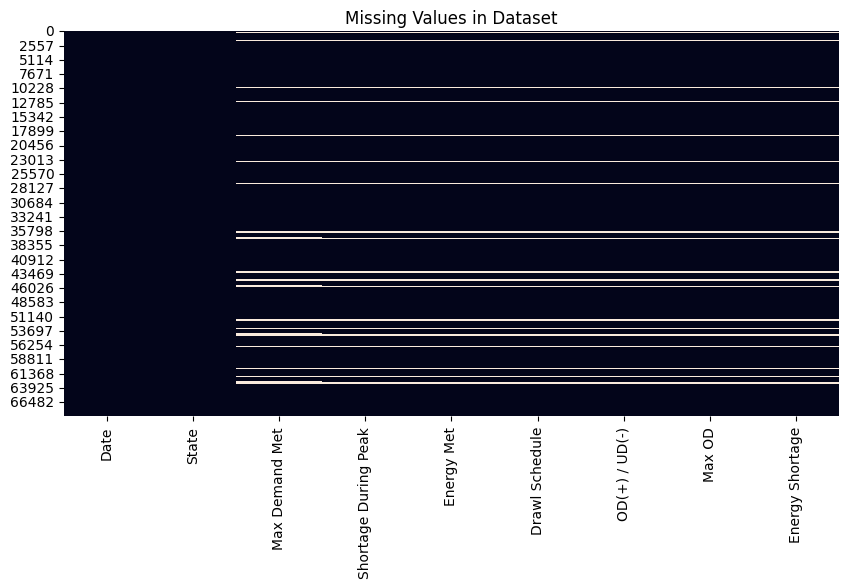

In [9]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Dataset")
plt.show()

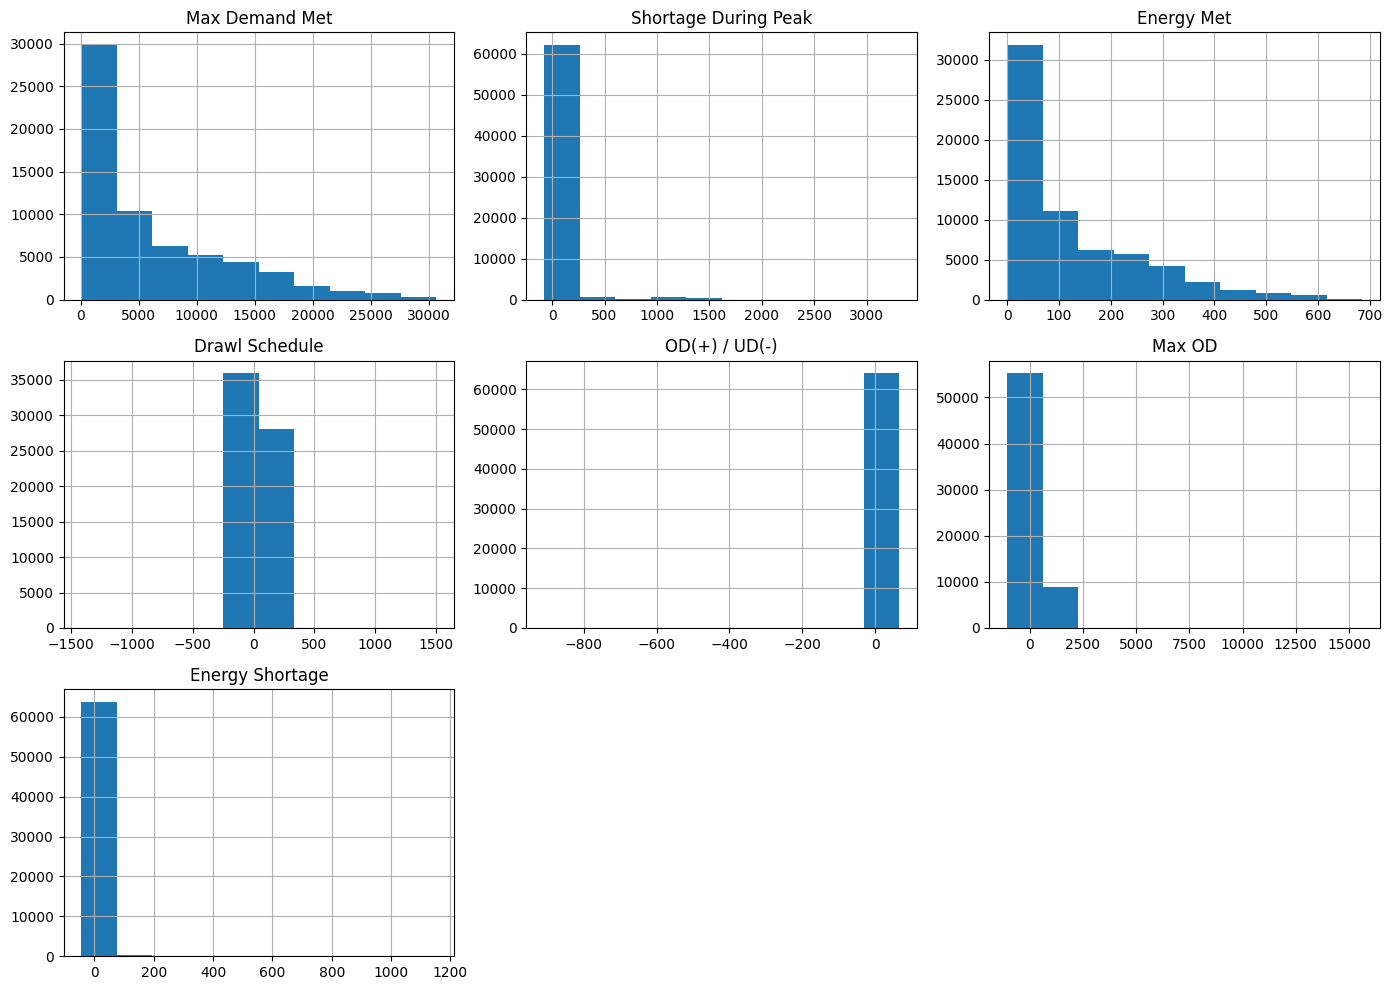

In [10]:
df.hist(figsize=(14, 10))
plt.tight_layout()
plt.show()

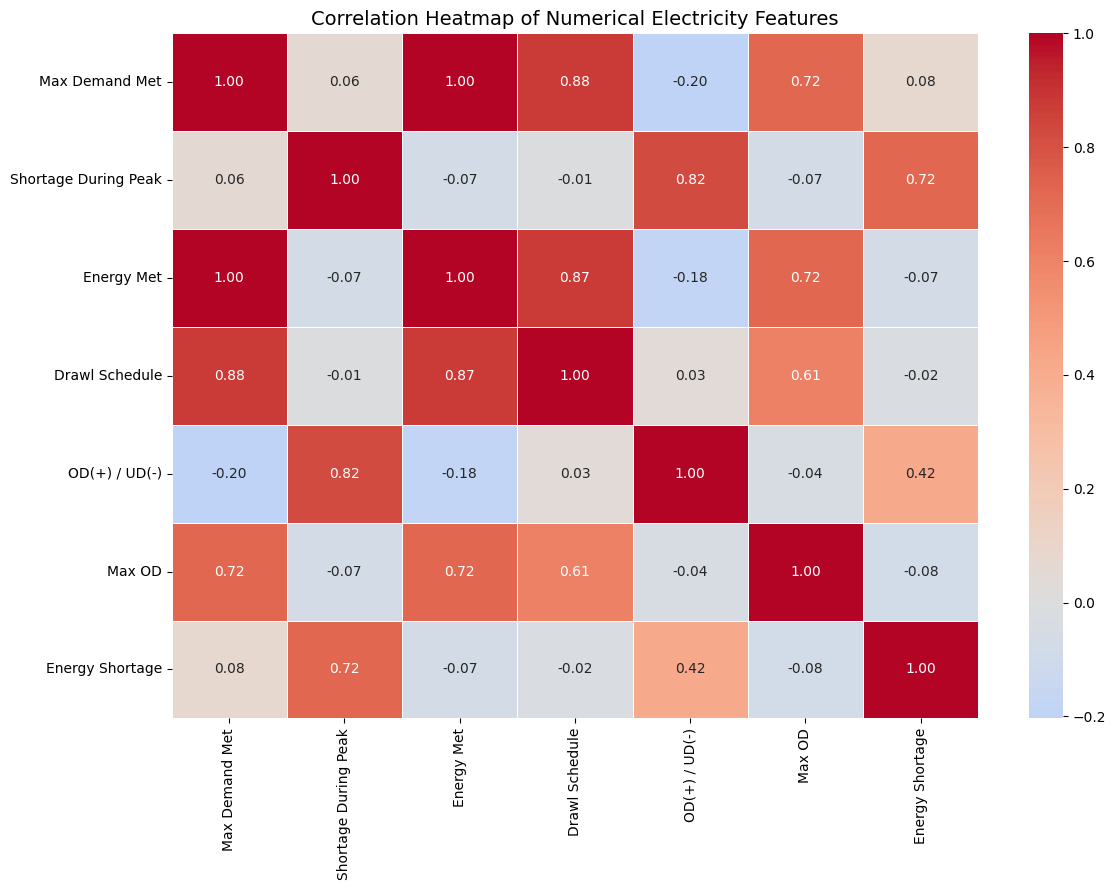

In [11]:
# GRAPH 2: NUMERIC FEATURE CORRELATION HEATMAP
# Helps inspect relationships between demand and related numeric variables

correlation_data = df.select_dtypes(include=np.number).copy()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_data.corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Numerical Electricity Features', fontsize=14)
plt.tight_layout()
plt.show()


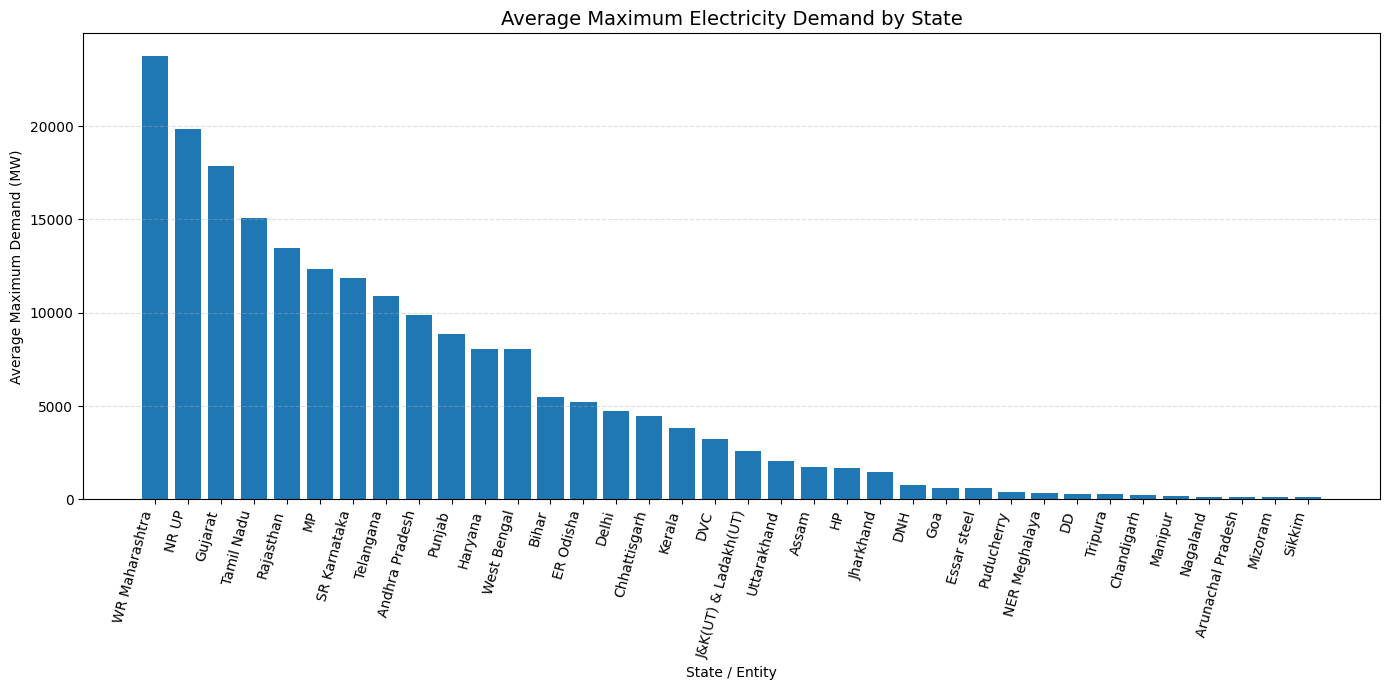

In [12]:
# GRAPH: STATE-WISE AVERAGE MAXIMUM ELECTRICITY DEMAND BAR CHART
# Compares average maximum electricity demand across states/entities

state_avg_demand = df.groupby('State')['Max Demand Met'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 7))
plt.bar(state_avg_demand.index, state_avg_demand.values)
plt.title('Average Maximum Electricity Demand by State', fontsize=14)
plt.xlabel('State / Entity')
plt.ylabel('Average Maximum Demand (MW)')
plt.xticks(rotation=75, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [13]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['State', 'Date'])
print("Date conversion completed!")
print("Starting Date:", df['Date'].min())
print("Ending Date:", df['Date'].max())
print("Number of States:", df['State'].nunique())

Date conversion completed!
Starting Date: 2020-01-01 00:00:00
Ending Date: 2025-03-31 00:00:00
Number of States: 36


In [14]:
date_gaps = df.groupby('State')['Date'].apply(
    lambda x: x.sort_values().diff().dt.days.value_counts()
)
print(date_gaps)

State                 Andhra Pradesh
Andhra Pradesh        1.0               1916
Arunachal Pradesh     1.0               1916
Assam                 1.0               1916
Bihar                 1.0               1916
Chandigarh            1.0               1916
Chhattisgarh          1.0               1916
DD                    1.0               1916
DNH                   1.0               1916
DVC                   1.0               1916
Delhi                 1.0               1916
ER Odisha             1.0               1916
Essar steel           1.0               1916
Goa                   1.0               1916
Gujarat               1.0               1916
HP                    1.0               1916
Haryana               1.0               1916
J&K(UT) & Ladakh(UT)  1.0               1916
Jharkhand             1.0               1916
Kerala                1.0               1916
MP                    1.0               1916
Manipur               1.0               1916
Mizoram           

In [15]:
print("Duplicate State-Date Records:",
      df.duplicated(subset=['State', 'Date']).sum())
print("\nRecords per State:")
print(df.groupby('State').size())

Duplicate State-Date Records: 0

Records per State:
State
Andhra Pradesh          1917
Arunachal Pradesh       1917
Assam                   1917
Bihar                   1917
Chandigarh              1917
Chhattisgarh            1917
DD                      1917
DNH                     1917
DVC                     1917
Delhi                   1917
ER Odisha               1917
Essar steel             1917
Goa                     1917
Gujarat                 1917
HP                      1917
Haryana                 1917
J&K(UT) & Ladakh(UT)    1917
Jharkhand               1917
Kerala                  1917
MP                      1917
Manipur                 1917
Mizoram                 1917
NER Meghalaya           1917
NR UP                   1917
Nagaland                1917
Puducherry              1917
Punjab                  1917
Rajasthan               1917
SR Karnataka            1917
Sikkim                  1917
Tamil Nadu              1917
Telangana               1917
Tripura       

In [16]:
df = df.dropna(subset=['Max Demand Met'])

print("Dataset after removing missing target values:")
print("Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

Dataset after removing missing target values:
Shape: (62972, 9)

Remaining Missing Values:
Date                    0
State                   0
Max Demand Met          0
Shortage During Peak    0
Energy Met              0
Drawl Schedule          0
OD(+) / UD(-)           0
Max OD                  4
Energy Shortage         0
dtype: int64


In [17]:
df = pd.read_csv("India_Elec_data_(Jan2020-Mar2025).csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['State', 'Date']).reset_index(drop=True)
print("Original dataset restored:", df.shape)

Original dataset restored: (69012, 9)


In [18]:
# ADVANCED HISTORICAL FEATURE ENGINEERING

df = pd.read_csv("India_Elec_data_(Jan2020-Mar2025).csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['State', 'Date']).reset_index(drop=True)

# Confirm daily date continuity within each reporting entity
gaps = df.groupby('State')['Date'].diff().dt.days.dropna()
if not (gaps == 1).all():
    print("Warning: some state/entity date gaps exist. Features will be created using row history; inspect gaps before interpreting results.")

g = df.groupby('State')['Max Demand Met']

# Lag features
df['Previous_Day_Demand'] = g.shift(1)
df['Demand_7_Days_Ago'] = g.shift(7)
df['Demand_14_Days_Ago'] = g.shift(14)
df['Demand_28_Days_Ago'] = g.shift(28)

# Rolling features use only historical values (shift by one first)
df['Seven_Day_Average'] = g.transform(lambda x: x.shift(1).rolling(7, min_periods=7).mean())
df['Fourteen_Day_Average'] = g.transform(lambda x: x.shift(1).rolling(14, min_periods=14).mean())
df['Thirty_Day_Average'] = g.transform(lambda x: x.shift(1).rolling(30, min_periods=30).mean())
df['Seven_Day_Std'] = g.transform(lambda x: x.shift(1).rolling(7, min_periods=7).std())

# Target and target date
df['Next_Day_Demand'] = g.shift(-1)
df['Next_Date'] = df.groupby('State')['Date'].shift(-1)

# Keep consecutive-day rows with all lag features available
required_columns = [
    'Next_Day_Demand', 'Previous_Day_Demand', 'Demand_7_Days_Ago',
    'Demand_14_Days_Ago', 'Demand_28_Days_Ago', 'Seven_Day_Average',
    'Fourteen_Day_Average', 'Thirty_Day_Average', 'Seven_Day_Std'
]
df = df[(df['Next_Date'] - df['Date']).dt.days == 1].copy()
df = df.dropna(subset=required_columns).copy()

print("Advanced historical features created!")
print("Dataset shape:", df.shape)
display(df.head())

Advanced historical features created!
Dataset shape: (44084, 19)


,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage,Previous_Day_Demand,Demand_7_Days_Ago,Demand_14_Days_Ago,Demand_28_Days_Ago,Seven_Day_Average,Fourteen_Day_Average,Thirty_Day_Average,Seven_Day_Std,Next_Day_Demand,Next_Date
90,2020-03-31,Andhra Pradesh,8296.0,0.0,164.2,85.4,-1.0,366.0,0.0,8244.0,9317.0,9967.0,9750.0,8445.857143,9121.142857,9359.300000,443.698632,8296.0,2020-04-01
91,2020-04-01,Andhra Pradesh,8296.0,0.0,164.2,85.4,-1.0,366.0,0.0,8296.0,8784.0,9980.0,9903.0,8300.000000,9001.785714,9308.566667,222.057800,8321.0,2020-04-02
92,2020-04-02,Andhra Pradesh,8321.0,0.0,163.7,91.0,-0.7,473.0,0.0,8296.0,8220.0,10207.0,10005.0,8230.285714,8881.500000,9259.700000,67.820140,8479.0,2020-04-03
93,2020-04-03,Andhra Pradesh,8479.0,0.0,165.8,91.1,0.2,501.0,0.0,8321.0,8217.0,10201.0,9982.0,8244.714286,8746.785714,9212.066667,75.568323,8424.0,2020-04-04
94,2020-04-04,Andhra Pradesh,8424.0,0.0,165.2,86.6,-0.5,395.0,0.0,8479.0,8095.0,9896.0,9790.0,8282.142857,8623.785714,9164.600000,114.439837,8222.0,2020-04-05


In [19]:
# CALENDAR AND CYCLIC FEATURES
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['DayOfYear'] = df['Date'].dt.dayofyear

# Cyclic encodings for seasonal calendar features
df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12)
df['DayOfWeek_Sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
df['DayOfWeek_Cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

print("Calendar and cyclic features created!")
display(df.head(10))

Calendar and cyclic features created!


,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage,Previous_Day_Demand,...,Next_Date,Year,Month,Day,DayOfWeek,DayOfYear,Month_Sin,Month_Cos,DayOfWeek_Sin,DayOfWeek_Cos
90,2020-03-31,Andhra Pradesh,8296.0,0.0,164.2,85.4,-1.0,366.0,0.0,8244.0,...,2020-04-01,2020,3,31,1,91,1.000000,6.123234e-17,0.781831,0.623490
91,2020-04-01,Andhra Pradesh,8296.0,0.0,164.2,85.4,-1.0,366.0,0.0,8296.0,...,2020-04-02,2020,4,1,2,92,0.866025,-5.000000e-01,0.974928,-0.222521
92,2020-04-02,Andhra Pradesh,8321.0,0.0,163.7,91.0,-0.7,473.0,0.0,8296.0,...,2020-04-03,2020,4,2,3,93,0.866025,-5.000000e-01,0.433884,-0.900969
93,2020-04-03,Andhra Pradesh,8479.0,0.0,165.8,91.1,0.2,501.0,0.0,8321.0,...,2020-04-04,2020,4,3,4,94,0.866025,-5.000000e-01,-0.433884,-0.900969
94,2020-04-04,Andhra Pradesh,8424.0,0.0,165.2,86.6,-0.5,395.0,0.0,8479.0,...,2020-04-05,2020,4,4,5,95,0.866025,-5.000000e-01,-0.974928,-0.222521
95,2020-04-05,Andhra Pradesh,8222.0,0.0,163.2,87.1,-0.2,483.0,0.0,8424.0,...,2020-04-06,2020,4,5,6,96,0.866025,-5.000000e-01,-0.781831,0.623490
96,2020-04-06,Andhra Pradesh,8595.0,0.0,164.1,93.9,0.8,628.0,0.0,8222.0,...,2020-04-07,2020,4,6,0,97,0.866025,-5.000000e-01,0.000000,1.000000
97,2020-04-07,Andhra Pradesh,8312.0,0.0,160.3,91.2,0.2,824.0,0.0,8595.0,...,2020-04-08,2020,4,7,1,98,0.866025,-5.000000e-01,0.781831,0.623490
98,2020-04-08,Andhra Pradesh,8095.0,0.0,155.6,89.5,0.3,677.0,0.0,8312.0,...,2020-04-09,2020,4,8,2,99,0.866025,-5.000000e-01,0.974928,-0.222521
99,2020-04-09,Andhra Pradesh,8095.0,0.0,155.6,89.5,0.3,677.0,0.0,8095.0,...,2020-04-10,2020,4,9,3,100,0.866025,-5.000000e-01,0.433884,-0.900969


In [20]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNew Feature Names:")
print(df.columns.tolist())

Dataset Shape: (44084, 28)

Missing Values:
Date                      0
State                     0
Max Demand Met          310
Shortage During Peak    304
Energy Met              302
Drawl Schedule          296
OD(+) / UD(-)           296
Max OD                  296
Energy Shortage         296
Previous_Day_Demand       0
Demand_7_Days_Ago         0
Demand_14_Days_Ago        0
Demand_28_Days_Ago        0
Seven_Day_Average         0
Fourteen_Day_Average      0
Thirty_Day_Average        0
Seven_Day_Std             0
Next_Day_Demand           0
Next_Date                 0
Year                      0
Month                     0
Day                       0
DayOfWeek                 0
DayOfYear                 0
Month_Sin                 0
Month_Cos                 0
DayOfWeek_Sin             0
DayOfWeek_Cos             0
dtype: int64

New Feature Names:
['Date', 'State', 'Max Demand Met', 'Shortage During Peak', 'Energy Met', 'Drawl Schedule', 'OD(+) / UD(-)', 'Max OD', 'Energy Shortage', '

In [21]:

# Chronological train-test split based on target dates
dates = sorted(df['Next_Date'].unique())
split_date = dates[int(len(dates) * 0.8)]

train_data = df[df['Next_Date'] < split_date].copy()
test_data = df[df['Next_Date'] >= split_date].copy()

print("Split Date:", split_date)
print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

print("\nTraining Target Date Range:")
print(train_data['Next_Date'].min(), "to", train_data['Next_Date'].max())

print("\nTesting Target Date Range:")
print(test_data['Next_Date'].min(), "to", test_data['Next_Date'].max())


Split Date: 2024-06-07 00:00:00
Training Data Shape: (35348, 28)
Testing Data Shape: (8736, 28)

Training Target Date Range:
2020-04-01 00:00:00 to 2024-06-06 00:00:00

Testing Target Date Range:
2024-06-07 00:00:00 to 2025-03-07 00:00:00


In [22]:
# UPDATED FEATURE SELECTION
feature_columns = [
    'State', 'Max Demand Met', 'Shortage During Peak', 'Energy Met',
    'Drawl Schedule', 'OD(+) / UD(-)', 'Max OD', 'Energy Shortage',
    'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear',
    'Month_Sin', 'Month_Cos', 'DayOfWeek_Sin', 'DayOfWeek_Cos',
    'Previous_Day_Demand', 'Demand_7_Days_Ago', 'Demand_14_Days_Ago',
    'Demand_28_Days_Ago', 'Seven_Day_Average', 'Fourteen_Day_Average',
    'Thirty_Day_Average', 'Seven_Day_Std'
]

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()
y_train = train_data['Next_Day_Demand']
y_test = test_data['Next_Day_Demand']

# One-hot encode the entity/state and align test columns to training columns
X_train = pd.get_dummies(X_train, columns=['State'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['State'], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Updated features prepared!")
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Updated features prepared!
Training Features: (35348, 60)
Testing Features: (8736, 60)


In [23]:
imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values handled successfully!")

print("Training Missing Values:", X_train.isnull().sum().sum())
print("Testing Missing Values:", X_test.isnull().sum().sum())

Missing values handled successfully!
Training Missing Values: 0
Testing Missing Values: 0


In [24]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

print("Multiple Linear Regression completed!")

Multiple Linear Regression completed!


In [25]:
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_predictions)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("----------------------------------")
print("MAE:", round(lr_mae, 2))
print("MSE:", round(lr_mse, 2))
print("RMSE:", round(lr_rmse, 2))
print("R2 Score:", round(lr_r2, 4))

MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------
MAE: 314.88
MSE: 352311.31
RMSE: 593.56
R2 Score: 0.9935


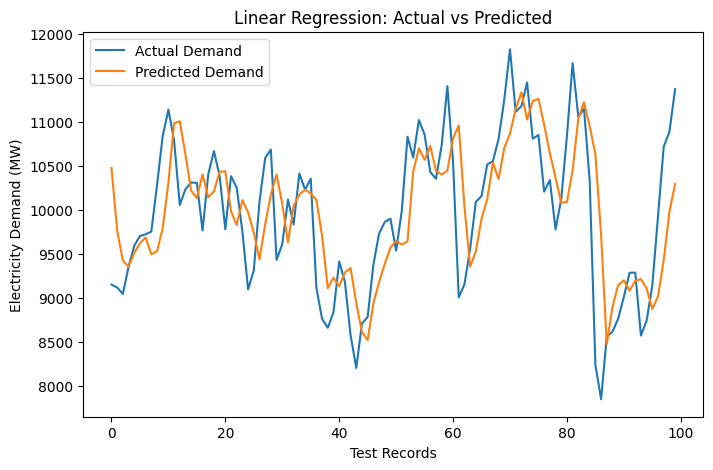

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(list(y_test.iloc[:100]),
         label='Actual Demand')

plt.plot(lr_predictions[:100],
         label='Predicted Demand')

plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Test Records")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.show()

In [27]:
# Calculate high-demand threshold for each state
state_thresholds = train_data.groupby('State')[
    'Next_Day_Demand'
].quantile(0.75)

# Create training labels
y_train_class = (
    train_data['Next_Day_Demand'] >=
    train_data['State'].map(state_thresholds)
).astype(int)

# Create testing labels using the same training thresholds
y_test_class = (
    test_data['Next_Day_Demand'] >=
    test_data['State'].map(state_thresholds)
).astype(int)

print("Classification labels created!")
print("\nTraining Classes:")
print(y_train_class.value_counts())

print("\nTesting Classes:")
print(y_test_class.value_counts())

Classification labels created!

Training Classes:
0    26440
1     8908
Name: count, dtype: int64

Testing Classes:
0    4585
1    4151
Name: count, dtype: int64


In [28]:
# HIGH-DEMAND CLASSIFIER: RANDOM FOREST + VALIDATION THRESHOLD TUNING
from sklearn.ensemble import RandomForestClassifier

# Use the last 20% of training dates as a validation period for threshold selection
class_dates = train_data.loc[X_train.index, 'Next_Date']
unique_class_dates = np.array(sorted(class_dates.unique()))
split_pos = int(len(unique_class_dates) * 0.80)
fit_dates = unique_class_dates[:split_pos]
val_dates = unique_class_dates[split_pos:]
fit_pos = np.where(class_dates.isin(fit_dates))[0]
val_pos = np.where(class_dates.isin(val_dates))[0]

if len(val_pos) == 0 or len(fit_pos) == 0:
    raise ValueError("Not enough training dates to create classifier validation split.")

classifier_for_threshold = RandomForestClassifier(
    n_estimators=300, max_depth=15, min_samples_leaf=2,
    class_weight='balanced', random_state=42, n_jobs=-1
)
classifier_for_threshold.fit(X_train.iloc[fit_pos], y_train_class.iloc[fit_pos])
val_probabilities = classifier_for_threshold.predict_proba(X_train.iloc[val_pos])[:, 1]
y_val_class = y_train_class.iloc[val_pos]

threshold_candidates = np.arange(0.20, 0.81, 0.02)
best_threshold = 0.50
best_validation_f1 = -1
for threshold in threshold_candidates:
    val_pred = (val_probabilities >= threshold).astype(int)
    score = f1_score(y_val_class, val_pred, zero_division=0)
    if score > best_validation_f1:
        best_validation_f1 = score
        best_threshold = threshold

# Refit classifier using all training rows; keep the test set untouched
dt_model = RandomForestClassifier(
    n_estimators=300, max_depth=15, min_samples_leaf=2,
    class_weight='balanced', random_state=42, n_jobs=-1
)
dt_model.fit(X_train, y_train_class)
test_probabilities = dt_model.predict_proba(X_test)[:, 1]
dt_predictions = (test_probabilities >= best_threshold).astype(int)

print("Random Forest high-demand classifier trained!")
print("Threshold selected on validation data:", round(best_threshold, 3))
print("Validation F1 at selected threshold:", round(best_validation_f1, 4))

Random Forest high-demand classifier trained!
Threshold selected on validation data: 0.34
Validation F1 at selected threshold: 0.7439


In [29]:
# CLASSIFIER TEST-SET EVALUATION
dt_accuracy = accuracy_score(y_test_class, dt_predictions)
dt_precision = precision_score(y_test_class, dt_predictions, zero_division=0)
dt_recall = recall_score(y_test_class, dt_predictions, zero_division=0)
dt_f1 = f1_score(y_test_class, dt_predictions, zero_division=0)

print("RANDOM FOREST HIGH-DEMAND CLASSIFICATION RESULTS")
print("-----------------------------------------------")
print("Accuracy:", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1 Score:", round(dt_f1, 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, dt_predictions))

RANDOM FOREST HIGH-DEMAND CLASSIFICATION RESULTS
-----------------------------------------------
Accuracy: 0.8076
Precision: 0.7193
Recall: 0.9759
F1 Score: 0.8282

Confusion Matrix:
[[3004 1581]
 [ 100 4051]]


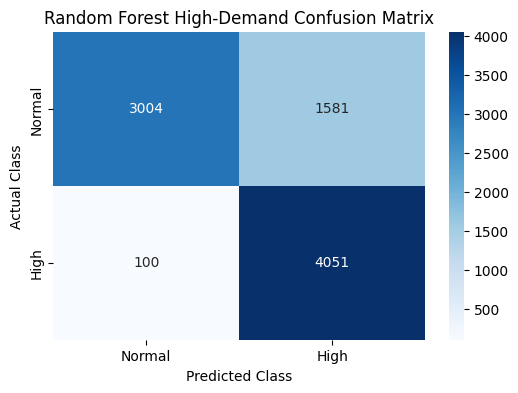

In [30]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test_class, dt_predictions),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'High'],
    yticklabels=['Normal', 'High']
)

plt.title("Random Forest High-Demand Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [31]:
cluster_features = [
    'Max Demand Met',
    'Energy Met',
    'Drawl Schedule',
    'Shortage During Peak',
    'Max OD',
    'Energy Shortage'
]

cluster_data = train_data.groupby('State')[cluster_features].mean()

print("State-wise clustering data:")
display(cluster_data.head())

print("Number of States:", cluster_data.shape[0])

State-wise clustering data:


,Max Demand Met,Energy Met,Drawl Schedule,Shortage During Peak,Max OD,Energy Shortage
State,,,,,,
Andhra Pradesh,10260.240803,203.539911,75.938239,13.265329,647.528428,0.266845
Arunachal Pradesh,145.220736,2.496656,2.431996,0.276477,37.651059,0.001494
Assam,1703.647276,30.520129,24.362142,12.350877,135.305633,0.250646
Bihar,5435.710988,103.191043,94.728717,60.395199,349.380425,0.972779
Chandigarh,248.855032,4.619760,4.732041,0.000000,29.065559,0.000000


Number of States: 36


In [32]:
cluster_imputer = SimpleImputer(strategy='median')

cluster_values = cluster_imputer.fit_transform(cluster_data)
cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_values)

print("Clustering data prepared successfully!")

Clustering data prepared successfully!


In [33]:
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
cluster_labels = kmeans_model.fit_predict(cluster_scaled)
cluster_data['Cluster'] = cluster_labels

print("K-Means Clustering completed!")
print("\nCluster Distribution:")
print(cluster_data['Cluster'].value_counts().sort_index())

K-Means Clustering completed!

Cluster Distribution:
Cluster
0     8
1    23
2     5
Name: count, dtype: int64


K-MEANS CLUSTERING RESULTS
--------------------------
Silhouette Score: 0.5652


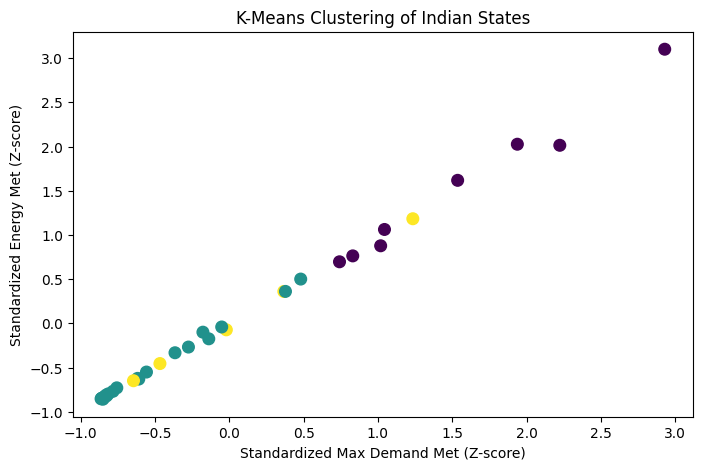

,Cluster
State,
Andhra Pradesh,0
Gujarat,0
NR UP,0
SR Karnataka,0
Tamil Nadu,0
Telangana,0
MP,0
WR Maharashtra,0
Essar steel,1


In [34]:
kmeans_silhouette = silhouette_score(
    cluster_scaled, cluster_labels
)

print("K-MEANS CLUSTERING RESULTS")
print("--------------------------")
print("Silhouette Score:", round(kmeans_silhouette, 4))
plt.figure(figsize=(8, 5))

plt.scatter(
    cluster_scaled[:, 0],
    cluster_scaled[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=70
)

plt.title("K-Means Clustering of Indian States")
plt.xlabel("Standardized Max Demand Met (Z-score)")
plt.ylabel("Standardized Energy Met (Z-score)")
plt.show()
display(cluster_data[['Cluster']].sort_values('Cluster'))

In [35]:
pca_scaler = StandardScaler()

X_train_scaled = pca_scaler.fit_transform(X_train)
X_test_scaled = pca_scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [36]:
pca_model = PCA(n_components=0.95)

X_train_pca = pca_model.fit_transform(X_train_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

print("PCA completed!")
print("Original Features:", X_train.shape[1])
print("Reduced Features:", X_train_pca.shape[1])

print("Explained Variance:",
      round(sum(pca_model.explained_variance_ratio_), 4))

PCA completed!
Original Features: 60
Reduced Features: 41
Explained Variance: 0.9501


In [37]:
mlp_model = MLPRegressor(
    hidden_layer_sizes=(50,),
    max_iter=300,
    random_state=42,
    early_stopping=True
)
mlp_model.fit(X_train_pca, y_train)
mlp_predictions = mlp_model.predict(X_test_pca)

print("PCA + Neural Network training completed!")

PCA + Neural Network training completed!


In [38]:
mlp_mae = mean_absolute_error(y_test, mlp_predictions)
mlp_mse = mean_squared_error(y_test, mlp_predictions)
mlp_rmse = np.sqrt(mlp_mse)
mlp_r2 = r2_score(y_test, mlp_predictions)

print("PCA + NEURAL NETWORK RESULTS")
print("----------------------------")
print("MAE:", round(mlp_mae, 2))
print("MSE:", round(mlp_mse, 2))
print("RMSE:", round(mlp_rmse, 2))
print("R2 Score:", round(mlp_r2, 4))

PCA + NEURAL NETWORK RESULTS
----------------------------
MAE: 469.86
MSE: 748074.23
RMSE: 864.91
R2 Score: 0.9862


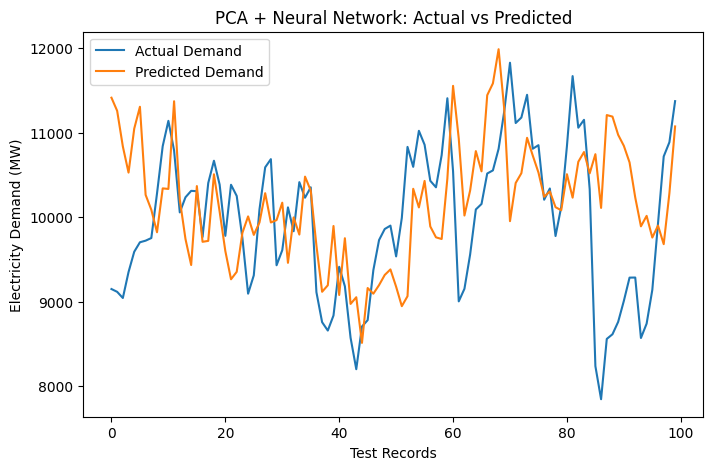

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(y_test.iloc[:100].values,
         label='Actual Demand')

plt.plot(mlp_predictions[:100],
         label='Predicted Demand')

plt.title("PCA + Neural Network: Actual vs Predicted")
plt.xlabel("Test Records")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.show()

In [40]:
# RANDOM FOREST REGRESSION: DATE-AWARE HYPERPARAMETER TUNING
from sklearn.model_selection import RandomizedSearchCV

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.7, 1.0]
}

# CV folds are created by target date so all entities from a date stay together
train_dates_rf = train_data.loc[X_train.index, 'Next_Date']
unique_dates_rf = np.array(sorted(train_dates_rf.unique()))
date_chunks_rf = np.array_split(unique_dates_rf, 4)
cv_folds_rf = []
for fold_num in range(1, len(date_chunks_rf)):
    prior_dates = np.concatenate(date_chunks_rf[:fold_num])
    val_dates_fold = date_chunks_rf[fold_num]
    train_pos_fold = np.where(train_dates_rf.isin(prior_dates))[0]
    val_pos_fold = np.where(train_dates_rf.isin(val_dates_fold))[0]
    if len(train_pos_fold) and len(val_pos_fold):
        cv_folds_rf.append((train_pos_fold, val_pos_fold))

search = RandomizedSearchCV(
    estimator=rf_base, param_distributions=param_grid,
    n_iter=12, scoring='neg_mean_absolute_error',
    cv=cv_folds_rf, random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
rf_model = search.best_estimator_
rf_predictions = rf_model.predict(X_test)

print("Random Forest tuning completed!")
print("Best parameters:", search.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Random Forest tuning completed!
Best parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': 20}


In [53]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST REGRESSION RESULTS")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST REGRESSION RESULTS
--------------------------------
MAE: 235.19
MSE: 219803.91
RMSE: 468.83
R2 Score: 0.9959


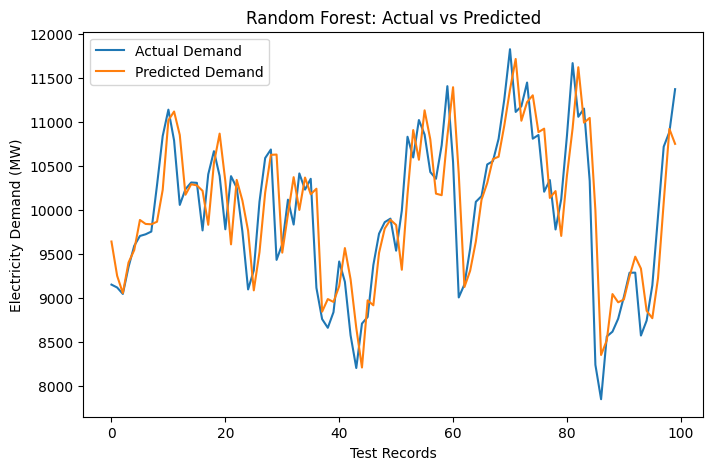

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(y_test.iloc[:100].values,
         label='Actual Demand')

plt.plot(rf_predictions[:100],
         label='Predicted Demand')

plt.title("Random Forest: Actual vs Predicted")
plt.xlabel("Test Records")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.show()

In [55]:
results = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Random Forest Classifier (High-Demand)',
        'K-Means Clustering',
        'PCA + Neural Network',
        'Random Forest Regression'
    ],
    'MAE': [
        lr_mae, np.nan, np.nan, mlp_mae, rf_mae
    ],
    'RMSE': [
        lr_rmse, np.nan, np.nan, mlp_rmse, rf_rmse
    ],
    'R2 Score': [
        lr_r2, np.nan, np.nan, mlp_r2, rf_r2
    ],
    'Accuracy': [
        np.nan, dt_accuracy, np.nan, np.nan, np.nan
    ],
    'F1 Score': [
        np.nan, dt_f1, np.nan, np.nan, np.nan
    ],
    'Silhouette Score': [
        np.nan, np.nan, kmeans_silhouette, np.nan, np.nan
    ]
})

print("OVERALL MODEL PERFORMANCE")
display(results.round(4))

OVERALL MODEL PERFORMANCE


,Model,MAE,RMSE,R2 Score,Accuracy,F1 Score,Silhouette Score
0,Multiple Linear Regression,314.8785,593.5582,0.9935,NaN,NaN,NaN
1,Random Forest Classifier (High-Demand),NaN,NaN,NaN,0.8076,0.8282,NaN
2,K-Means Clustering,NaN,NaN,NaN,NaN,NaN,0.5652
3,PCA + Neural Network,469.8614,864.9128,0.9862,NaN,NaN,NaN
4,Random Forest Regression,235.1882,468.8325,0.9959,NaN,NaN,NaN


TOP 10 IMPORTANT FEATURES


,Feature,Importance
16,Previous_Day_Demand,0.586741
20,Seven_Day_Average,0.176496
0,Max Demand Met,0.138994
21,Fourteen_Day_Average,0.081896
22,Thirty_Day_Average,0.009634
2,Energy Met,0.003260
17,Demand_7_Days_Ago,0.000926
14,DayOfWeek_Sin,0.000376
18,Demand_14_Days_Ago,0.000291
23,Seven_Day_Std,0.000168


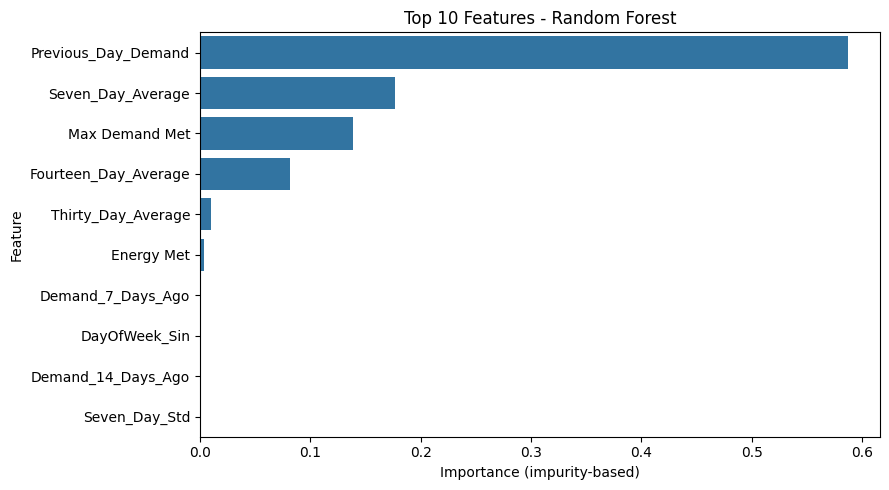

In [56]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 10 IMPORTANT FEATURES")
display(importance.head(10))

# Plot feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Features - Random Forest")
plt.xlabel("Importance (impurity-based)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [57]:
# Save model comparison results
results.to_csv('Model_Comparison_Results.csv', index=False)

# Save feature importance
importance.to_csv('Feature_Importance.csv', index=False)

# Save cleaned forecasting dataset
df.to_csv('Electricity_Forecasting_Cleaned.csv', index=False)

print("Project results saved successfully!")

Project results saved successfully!


In [58]:
# Keep only records where today's and next day's demand are available
valid_rows = test_data['Max Demand Met'].notna()

# Actual next-day demand
baseline_actual = test_data.loc[valid_rows, 'Next_Day_Demand']

# Predict tomorrow's demand using today's demand
baseline_predictions = test_data.loc[
    valid_rows, 'Max Demand Met'
]

# Calculate metrics
baseline_mae = mean_absolute_error(
    baseline_actual, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_predictions)
)

baseline_r2 = r2_score(
    baseline_actual, baseline_predictions
)

print("NAIVE FORECASTING BASELINE")
print("--------------------------")
print("Records evaluated:", len(baseline_actual))
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R2 Score:", round(baseline_r2, 4))

NAIVE FORECASTING BASELINE
--------------------------
Records evaluated: 8704
MAE: 258.91
RMSE: 525.39
R2 Score: 0.9949


In [59]:
# Select predictions for the same valid test records
valid_indices = test_data.index[valid_rows]

lr_valid = pd.Series(lr_predictions, index=X_test.index).loc[valid_indices]
mlp_valid = pd.Series(mlp_predictions, index=X_test.index).loc[valid_indices]
rf_valid = pd.Series(rf_predictions, index=X_test.index).loc[valid_indices]

actual = baseline_actual

validation_results = pd.DataFrame({
    'Model': [
        'Naive Baseline',
        'Linear Regression',
        'PCA + MLP',
        'Random Forest'
    ],
    'MAE': [
        baseline_mae,
        mean_absolute_error(actual, lr_valid),
        mean_absolute_error(actual, mlp_valid),
        mean_absolute_error(actual, rf_valid)
    ],
    'RMSE': [
        baseline_rmse,
        np.sqrt(mean_squared_error(actual, lr_valid)),
        np.sqrt(mean_squared_error(actual, mlp_valid)),
        np.sqrt(mean_squared_error(actual, rf_valid))
    ],
    'R2 Score': [
        baseline_r2,
        r2_score(actual, lr_valid),
        r2_score(actual, mlp_valid),
        r2_score(actual, rf_valid)
    ]
})

display(validation_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Naive Baseline,258.9057,525.3871,0.9949
1,Linear Regression,308.6915,568.5873,0.9940
2,PCA + MLP,465.5494,854.2565,0.9865
3,Random Forest,234.1095,465.3219,0.9960


In [60]:
# Save final validation comparison
validation_results.to_csv(
    'Final_Validation_Results.csv',
    index=False
)

print("Final validation results saved successfully!")

Final validation results saved successfully!


In [61]:
all_states = sorted(pd.read_csv("India_Elec_data_(Jan2020-Mar2025).csv")['State'].unique())
sr = test_data[['State', 'Next_Day_Demand']].copy()
sr['Pred'] = rf_predictions
state_results = sr.groupby('State').apply(lambda x: pd.Series({
    'Test_Observations': len(x),
    'MAE': mean_absolute_error(x['Next_Day_Demand'], x['Pred']),
    'RMSE': np.sqrt(mean_squared_error(x['Next_Day_Demand'], x['Pred'])),
    'Mean_Actual_MW': x['Next_Day_Demand'].mean()}), include_groups=False).reset_index()
state_results['RMSE_pct_of_mean'] = 100 * state_results['RMSE'] / state_results['Mean_Actual_MW']
display(state_results.sort_values('RMSE', ascending=False).round(2))

# Evidence for entities that are missing from the table
counts = test_data['State'].value_counts().reindex(all_states, fill_value=0)
print("Entities with zero test observations:", counts[counts == 0].index.tolist())
print("Reporting entities:", int((counts > 0).sum()), "of", len(all_states))
state_results.to_csv('State_Wise_RF_Results.csv', index=False)

,State,Test_Observations,MAE,RMSE,Mean_Actual_MW,RMSE_pct_of_mean
10,Gujarat,273.0,710.61,1002.96,20343.75,4.93
19,NR UP,273.0,722.54,990.59,22581.99,4.39
30,WR Maharashtra,273.0,734.72,951.79,25579.76,3.72
22,Punjab,273.0,541.18,840.23,10996.95,7.64
26,Tamil Nadu,273.0,566.97,770.39,16257.15,4.74
24,SR Karnataka,273.0,530.43,686.84,13089.38,5.25
23,Rajasthan,273.0,452.80,643.27,15577.86,4.13
15,MP,273.0,392.84,635.71,14148.04,4.49
12,Haryana,273.0,443.27,620.71,9616.75,6.45
27,Telangana,273.0,434.75,619.14,12460.90,4.97


Entities with zero test observations: ['DD', 'DNH', 'Essar steel', 'Jharkhand']
Reporting entities: 32 of 36


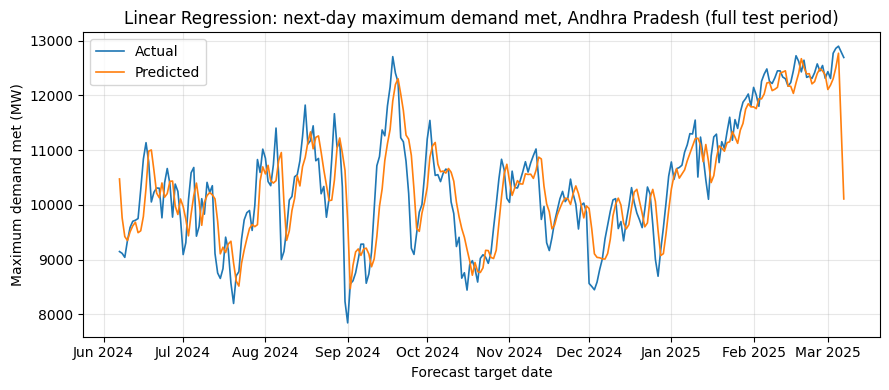

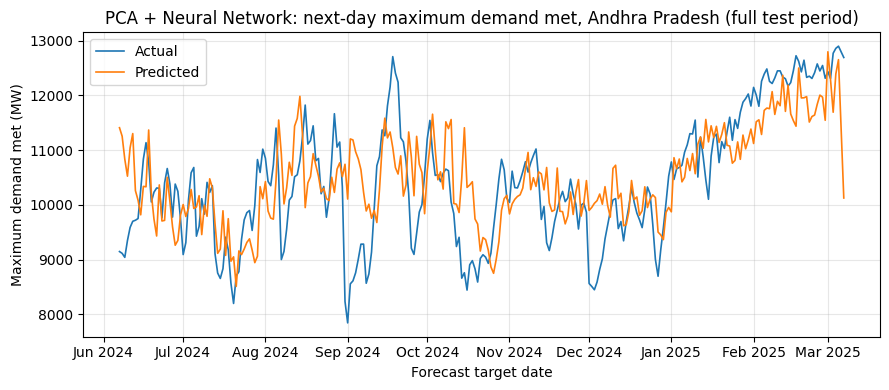

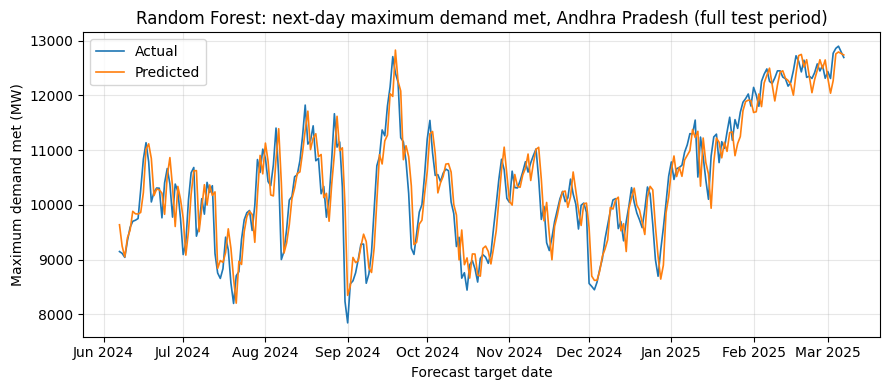

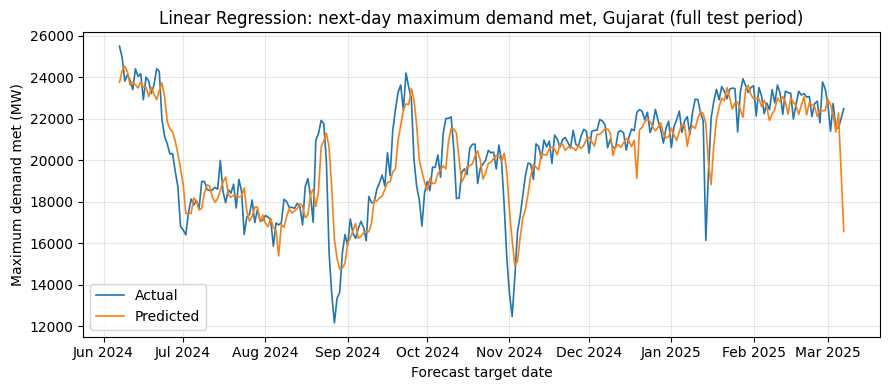

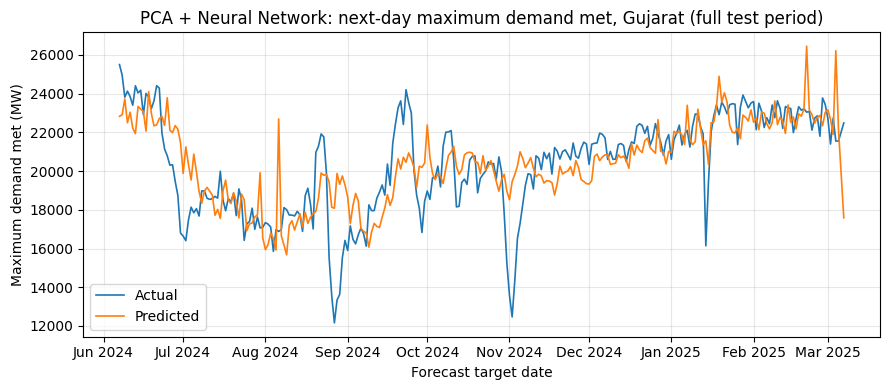

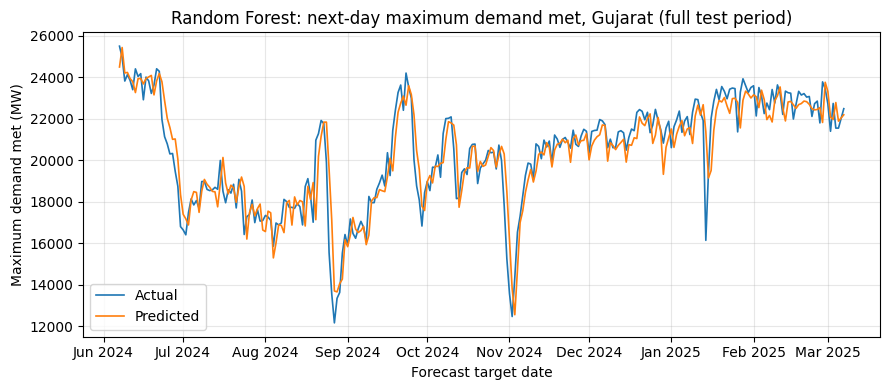

In [62]:
import matplotlib.dates as mdates

def plot_forecast(state, preds, name, fname):
    m = (test_data['State'] == state).values
    d = test_data.loc[m, 'Next_Date']
    y = test_data.loc[m, 'Next_Day_Demand']
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(d, y, label='Actual', lw=1.2)
    ax.plot(d, preds[m], label='Predicted', lw=1.2)
    ax.set_title(f'{name}: next-day maximum demand met, {state} (full test period)')
    ax.set_xlabel('Forecast target date')
    ax.set_ylabel('Maximum demand met (MW)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend()
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(fname, dpi=300)
    plt.show()

for st in ['Andhra Pradesh', 'Gujarat']:          # one mid-size and one large entity
    plot_forecast(st, lr_predictions,  'Linear Regression', f'fig_lr_{st}.png')
    plot_forecast(st, mlp_predictions, 'PCA + Neural Network', f'fig_mlp_{st}.png')
    plot_forecast(st, rf_predictions,  'Random Forest', f'fig_rf_{st}.png')

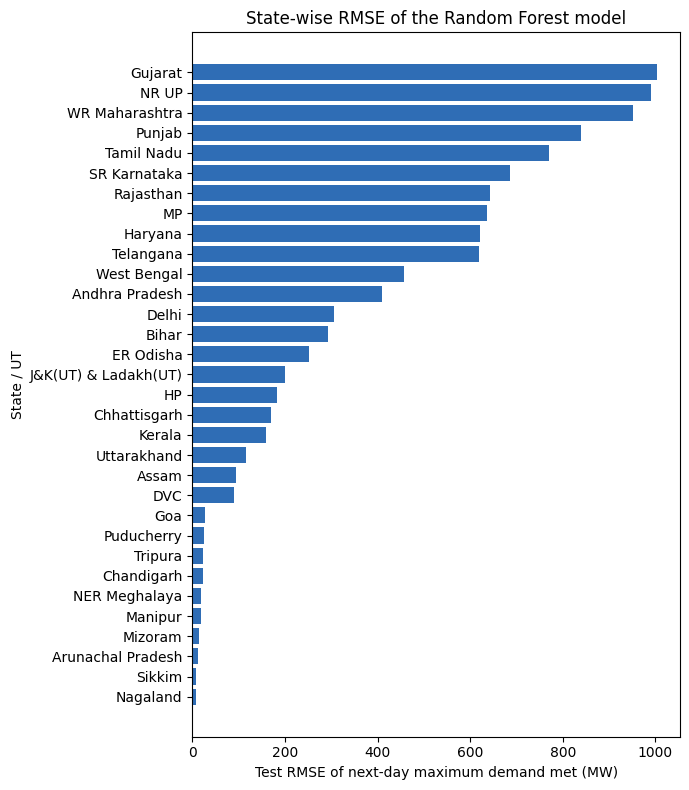

In [63]:
# State-wise RMSE bar chart
s = state_results.sort_values('RMSE')
plt.figure(figsize=(7, 8))
plt.barh(s['State'], s['RMSE'], color='#2F6DB5')
plt.xlabel('Test RMSE of next-day maximum demand met (MW)')
plt.ylabel('State / UT')
plt.title('State-wise RMSE of the Random Forest model')
plt.tight_layout()
plt.savefig('fig_statewise_rmse.png', dpi=300)
plt.show()

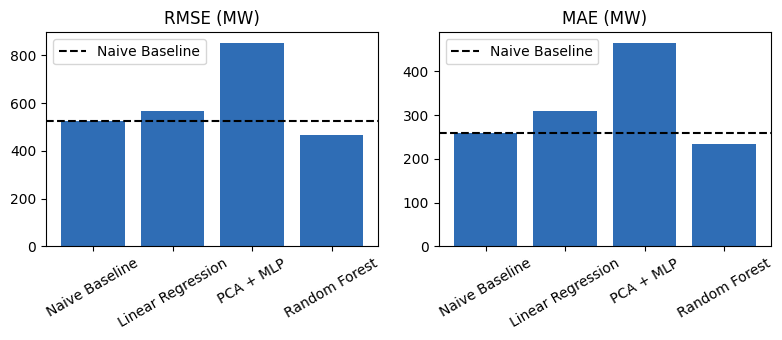

In [64]:
# Baseline comparison bar chart
v = validation_results.set_index('Model')
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, c in zip(ax, ['RMSE', 'MAE']):
    a.bar(v.index, v[c], color='#2F6DB5')
    a.axhline(v.loc['Naive Baseline', c], ls='--', c='k', label='Naive Baseline')
    a.set_title(f'{c} (MW)')
    a.tick_params(axis='x', rotation=30)
    a.legend()
plt.tight_layout()
plt.savefig('fig_baseline.png', dpi=300)
plt.show()